<a href="https://colab.research.google.com/github/mariamalktbi2005-cloud/Hotel-Booking-Cancellation-prediction/blob/main/hotel_booking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving hotel_bookings.csv to hotel_bookings.csv


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

# Import dataset
df = pd.read_csv("hotel_bookings.csv")

# Handle missing values
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")

# Remove unnecessary columns
df = df.drop(columns=["agent", "company"])

# Standardize text values
for col in df.select_dtypes("object"):
    df[col] = df[col].str.strip()

# Remove invalid records
df = df[
    (df["adults"] + df["children"] + df["babies"] > 0)
    & (df["adr"] >= 0)
    & (df["lead_time"] >= 0)
].copy()

# Feature engineering
df["total_guests"] = (
    df["adults"] + df["children"] + df["babies"]
)

df["total_nights"] = (
    df["stays_in_weekend_nights"]
    + df["stays_in_week_nights"]
)

# Prediction features
features = [
    "lead_time", "total_guests", "total_nights",
    "adr", "previous_cancellations",
    "previous_bookings_not_canceled",
    "hotel", "deposit_type", "market_segment",
    "arrival_date_month", "reserved_room_type",
    "customer_type"
]

# Group identical predictor combinations
groups = pd.util.hash_pandas_object(
    df[features], index=False
)

# Split the dataset
split = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

tr, te = next(
    split.split(df, df["is_canceled"], groups)
)

train = df.iloc[tr]
test = df.iloc[te]

print("Cleaned dataset:", df.shape)
print("Training records:", len(train))
print("Testing records:", len(test))

Cleaned dataset: (119209, 32)
Training records: 95278
Testing records: 23931


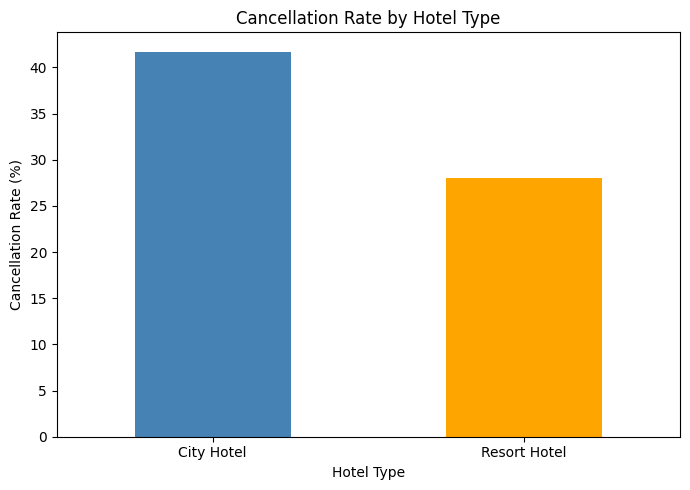

In [3]:
hotel_rate = train.groupby("hotel")["is_canceled"].mean() * 100

hotel_rate.plot(
    kind="bar",
    color=["steelblue", "orange"],
    figsize=(7, 5)
)

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("hotel_cancellation.png", dpi=300)
plt.show()

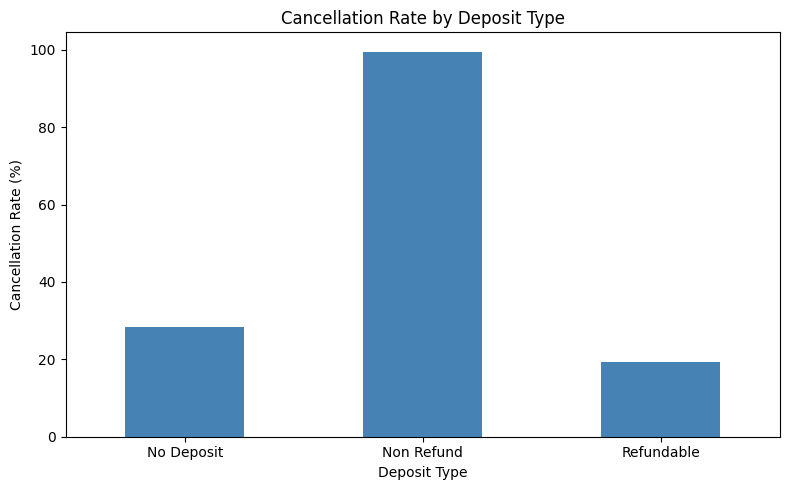

In [4]:
deposit_rate = (
    train.groupby("deposit_type")["is_canceled"].mean() * 100
)

deposit_rate.plot(
    kind="bar",
    color="steelblue",
    figsize=(8, 5)
)

plt.title("Cancellation Rate by Deposit Type")
plt.xlabel("Deposit Type")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("deposit_cancellation.png", dpi=300)
plt.show()

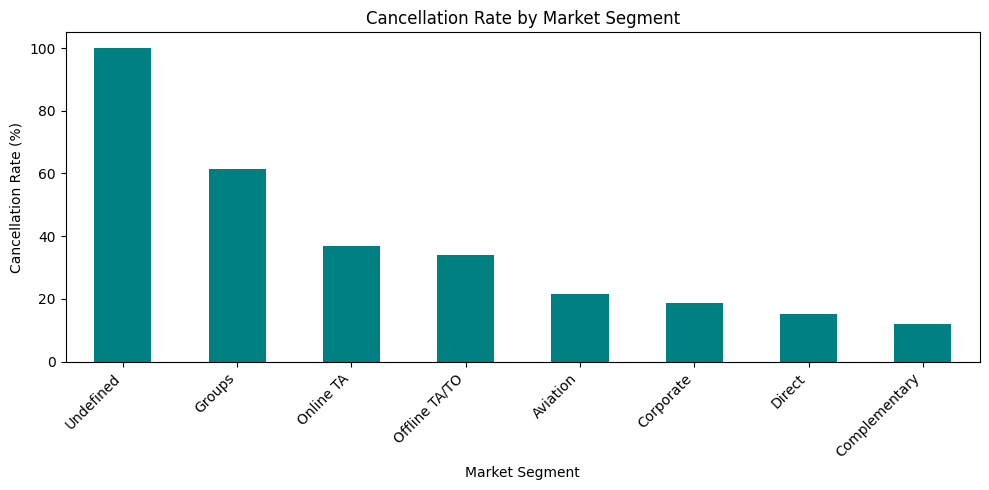

In [5]:
segment_rate = (
    train.groupby("market_segment")["is_canceled"].mean() * 100
)

segment_rate = segment_rate.sort_values(ascending=False)

segment_rate.plot(
    kind="bar",
    color="teal",
    figsize=(10, 5)
)

plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("market_segment.png", dpi=300)
plt.show()

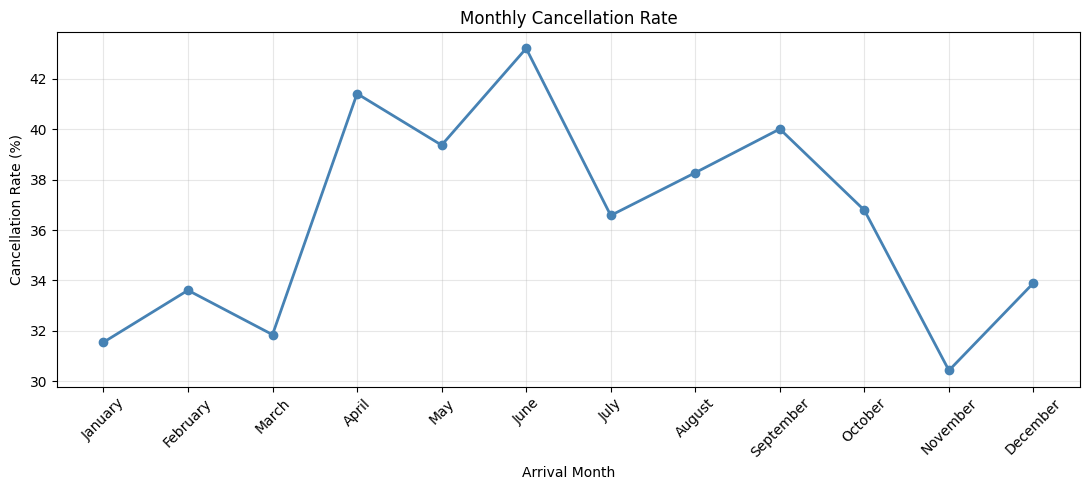

In [7]:
months = [
    "January", "February", "March",
    "April", "May", "June",
    "July", "August", "September",
    "October", "November", "December"
]

monthly_rate = (
    train.groupby("arrival_date_month")["is_canceled"].mean() * 100
)

monthly_rate = monthly_rate.reindex(months)

plt.figure(figsize=(11, 5))

plt.plot(
    monthly_rate.index,
    monthly_rate.values,
    marker="o",
    color="steelblue",
    linewidth=2
)

plt.title("Monthly Cancellation Rate")
plt.xlabel("Arrival Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("monthly_cancellation.png", dpi=300)
plt.show()

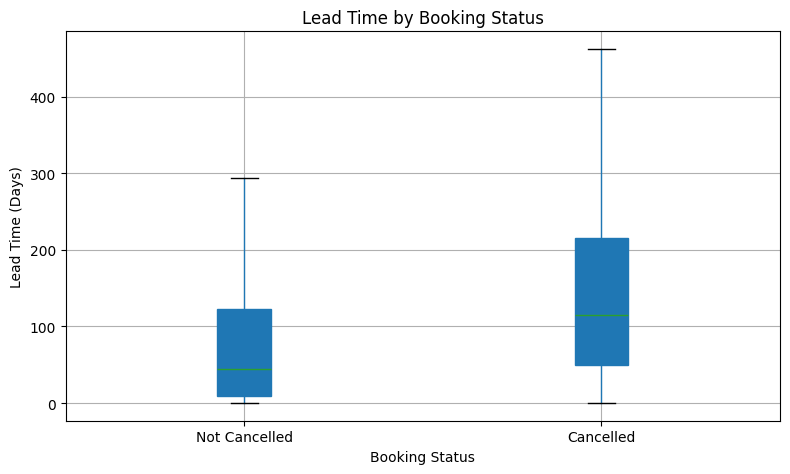

In [8]:
train.boxplot(
    column="lead_time",
    by="is_canceled",
    figsize=(8, 5),
    showfliers=False,
    patch_artist=True
)

plt.suptitle("")
plt.title("Lead Time by Booking Status")
plt.xlabel("Booking Status")
plt.ylabel("Lead Time (Days)")

plt.xticks(
    [1, 2],
    ["Not Cancelled", "Cancelled"]
)

plt.tight_layout()
plt.savefig("lead_time.png", dpi=300)
plt.show()

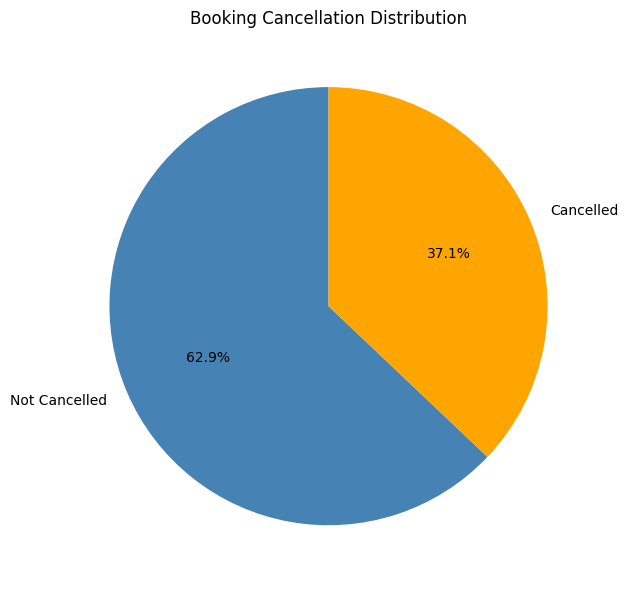

In [9]:
booking_counts = train["is_canceled"].value_counts().sort_index()

plt.figure(figsize=(7, 6))

plt.pie(
    booking_counts.values,
    labels=["Not Cancelled", "Cancelled"],
    autopct="%1.1f%%",
    colors=["steelblue", "orange"],
    startangle=90
)

plt.title("Booking Cancellation Distribution")
plt.tight_layout()

plt.savefig("cancellation_distribution.png", dpi=300)
plt.show()